# **This Project is just to see How a Neural Network model is built and trained using tensorflow and keras not to get the best model and high accuracy score**

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [19]:
data = pd.read_csv("Churn_Modelling.csv")
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [20]:
data.drop(columns=["RowNumber", "CustomerId", "Surname"], inplace=True)
data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [21]:
data.shape

(10000, 11)

In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  object 
 2   Gender           10000 non-null  object 
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 859.5+ KB


In [23]:
data.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [24]:
data['Geography'].value_counts()

,count
Geography,
France,5014
Germany,2509
Spain,2477


In [25]:
data['Gender'].value_counts()

,count
Gender,
Male,5457
Female,4543


In [26]:
from tensorflow import as_dtype
data = pd.get_dummies(data, columns=['Geography', 'Gender'], dtype=int)
data.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,1,0,0,1,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,0,1,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,1,0,0,1,0
3,699,39,1,0.00,2,0,0,93826.63,0,1,0,0,1,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,0,1,1,0


In [27]:
data.shape

(10000, 14)

In [28]:
X_train, X_test, y_train, y_test = train_test_split(data.drop(columns=["Exited"]), data["Exited"], test_size=0.2, random_state=42)

In [29]:
scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)

In [30]:
X_train

array([[ 0.35649971, -0.6557859 ,  0.34567966, ..., -0.57638802,
        -0.91324755,  0.91324755],
       [-0.20389777,  0.29493847, -0.3483691 , ..., -0.57638802,
        -0.91324755,  0.91324755],
       [-0.96147213, -1.41636539, -0.69539349, ...,  1.73494238,
        -0.91324755,  0.91324755],
       ...,
       [ 0.86500853, -0.08535128, -1.38944225, ..., -0.57638802,
         1.09499335, -1.09499335],
       [ 0.15932282,  0.3900109 ,  1.03972843, ..., -0.57638802,
        -0.91324755,  0.91324755],
       [ 0.47065475,  1.15059039, -1.38944225, ..., -0.57638802,
        -0.91324755,  0.91324755]])

In [41]:
model = Sequential()

model.add(Dense(6, activation="relu", input_dim=13))
model.add(Dense(6, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [42]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 6)              │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 133 (532.00 B)

 Trainable params: 133 (532.00 B)

 Non-trainable params: 0 (0.00 B)

In [43]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [44]:
history = model.fit(X_train, y_train, verbose=1, epochs=100, validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6189 - loss: 0.6583 - val_accuracy: 0.7987 - val_loss: 0.5515
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7933 - loss: 0.5094 - val_accuracy: 0.7987 - val_loss: 0.4711
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7934 - loss: 0.4630 - val_accuracy: 0.7987 - val_loss: 0.4412
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7933 - loss: 0.4410 - val_accuracy: 0.8000 - val_loss: 0.4270
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7950 - loss: 0.4300 - val_accuracy: 0.8125 - val_loss: 0.4197
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8133 - loss: 0.4229 - val_accuracy: 0.8294 - val_loss: 0.4138
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8255 - loss: 0.4159 - val_accuracy: 0.8313 - val_loss: 0.4082
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8269 - loss: 0.4096 - val_accu

In [52]:
model.layers[0].get_weights()

[array([[ 0.17017382, -0.08221717,  0.06110023, -0.02242124,  0.04122958,
          0.0522314 ],
        [ 0.5347953 ,  0.3396979 , -0.4291765 , -0.05698973, -0.2163382 ,
         -0.99575907],
        [ 0.16366833, -0.0151462 , -0.31633347,  0.06204512,  0.04685769,
          0.08015715],
        [-0.56415653,  0.03087085, -0.31261364, -0.40517554, -0.47478524,
         -0.02232179],
        [-0.37549043, -0.70536983, -0.30373582, -0.39135605, -1.6220628 ,
         -0.45151538],
        [ 0.08968055,  0.18053955, -0.3459435 , -0.04703077,  0.00806807,
          0.08293461],
        [ 0.5543508 ,  1.1590697 , -0.02270812, -0.02666108, -0.0017952 ,
         -0.34131262],
        [-0.03072784,  0.23321685,  0.11287339, -0.23614055,  0.05808998,
          0.06706446],
        [-0.14392437, -0.14324358,  0.00271348,  0.55498785,  0.2654883 ,
          0.40577462],
        [-0.06878531,  0.13049082,  0.43428972,  0.02089666,  0.561406  ,
          0.44720206],
        [ 0.08637883, -0.11845

In [53]:
model.layers[1].get_weights()

[array([[ 0.47631335,  1.1257085 ,  0.00303388, -0.2959404 , -0.3185622 ,
         -0.02388771],
        [ 0.9936124 ,  0.92727   , -1.405947  ,  0.40178004,  0.6301102 ,
          0.5050663 ],
        [ 0.36343333,  0.23513414, -0.9775435 ,  0.2548491 , -0.18942495,
         -0.3125554 ],
        [ 0.7586993 , -0.09472178, -0.35773912,  1.0777761 ,  0.15453768,
          0.3021958 ],
        [-0.91807705, -0.7848107 ,  0.27762675, -0.91590863, -1.1968355 ,
          1.1962423 ],
        [-0.07246197,  0.69952285, -1.1265686 ,  0.92838603, -1.2103429 ,
         -1.124251  ]], dtype=float32),
 array([ 0.11782285,  0.00690212,  1.1489956 ,  0.07966468, -0.15155143,
         0.45655122], dtype=float32)]

In [54]:
model.layers[2].get_weights()

[array([[-0.77323985],
        [-0.605451  ],
        [ 2.7655878 ],
        [-0.6222589 ],
        [ 1.3541204 ],
        [ 1.1302001 ]], dtype=float32),
 array([0.32551464], dtype=float32)]

In [56]:
print("Break")

Break


In [57]:
y_probab = model.predict(X_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


In [58]:
y_probab

array([[0.05279049],
       [0.02637683],
       [0.10684735],
       ...,
       [0.70428216],
       [0.08976045],
       [0.22903728]], dtype=float32)

In [59]:
y_pred = np.where(y_probab > 0.5, 1, 0)

In [60]:
y_pred

array([[0],
       [0],
       [0],
       ...,
       [1],
       [0],
       [0]])

In [61]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.8535

**plotting the loss and val_loss history**

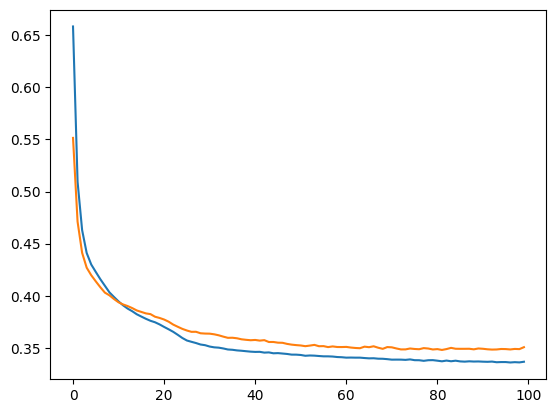

In [63]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

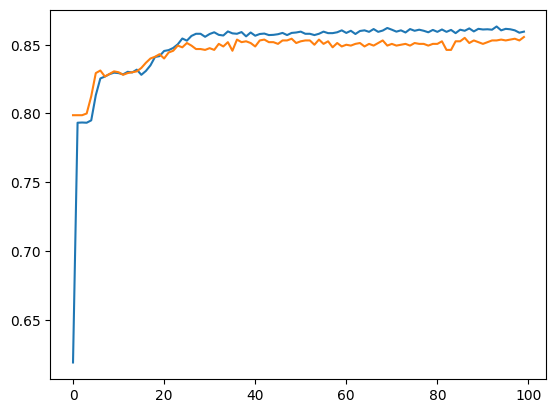

In [64]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])